In [ ]:
print('hi')

hi


In [ ]:
!python 02_fairface_all.py \
      --crops_zip /content/expw_crops.zip \
      --model_pt  /content/res34_fair_align_multi_7_20190809.pt \
      --out_csv   /content/fairface_all.csv

env: Colab | device: cuda (Tesla T4)
crops ready in /tmp/expw_full (6s)
manifest rows: 29546
FairFace checkpoint loaded (strict).
  batch 1/116 (5s)
  batch 21/116 (17s)
  batch 41/116 (31s)
  batch 61/116 (45s)
  batch 81/116 (59s)
  batch 101/116 (72s)
inference done in 81s

=== FAIRFACE SUMMARY ===
status: {'ok': 29546}

race:
 race_prediction
White              15154
Middle Eastern      4468
East Asian          3651
Black               2782
Latino_Hispanic     1475
Southeast Asian     1026
Indian               990

gender:
 gender_prediction
Male      16330
Female    13216

age:
 age_group_prediction
20-29    12957
30-39     4428
40-49     3274
10-19     2306
50-59     2129
3-9       1950
60-69     1494
0-2        539
70+        469
race_confidence: mean 0.738 | <0.5: 5556
gender_confidence: mean 0.949 | <0.5: 0
age_group_confidence: mean 0.554 | <0.5: 12215
flagged crops: 4631 | clean: 24915
saved: /content/fairface_all.csv


In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!mkdir -p /content/ctx_dev /content/ctx_core

In [ ]:
!unzip -q /content/dev_set_context_images.zip -d /content/ctx_dev
!unzip -q /content/core_set_context_images.zip -d /content/ctx_core

In [ ]:
!cp /content/*.py /content/
%cd /content
!pip install -q retina-face tf-keras

cp: '/content/05_match_and_jobs.py' and '/content/05_match_and_jobs.py' are the same file
cp: '/content/06_score_labels.py' and '/content/06_score_labels.py' are the same file
cp: '/content/07_dev_metrics.py' and '/content/07_dev_metrics.py' are the same file
cp: '/content/sov_stage1_2_detect.py' and '/content/sov_stage1_2_detect.py' are the same file
cp: '/content/Sov_stage3_5_overlay.py' and '/content/Sov_stage3_5_overlay.py' are the same file
/content


In [ ]:
import tensorflow as tf
import keras
import retinaface

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("RetinaFace:", retinaface.__file__)

TensorFlow: 2.21.0
Keras: 3.13.2
RetinaFace: /usr/local/lib/python3.13/dist-packages/retinaface/__init__.py


In [ ]:
%pip install tf-keras

In [ ]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [ ]:
!python sov_stage1_2_detect.py --input /content/ctx_dev/images --output /content/ctx_dev/det
!python Sov_stage3_5_overlay.py --input /content/ctx_dev/images --detections /content/ctx_dev/det/detections --output /content/ctx_dev/overlay --eps 0.4

12:15:28 INFO Found 280 image(s). Settings: {'backend': 'retinaface', 'threshold': 0.9, 'max_side': 1600}
W0000 00:00:1793103328.894095    7911 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
26-10-27 12:15:31 - Directory /root/.deepface/weights created
26-10-27 12:15:31 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5
100% 119M/119M [00:00<00:00, 119MB/s]
W0000 00:00:1793103335.236988    7947 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: goo.gle/debugonly  
batch: 1
in_depths: 64
out_depths: 64
in: 258
in: 258
data_format: 1
filter: 3
filter: 3
filter: 64
dilation: 1
dilation: 1
str

In [ ]:
!python 05_match_and_jobs.py --targets /content/ctx_dev/targets.csv --overlay_root /content/ctx_dev/overlay --name dev --variants A,B --conditions plain,sov

targets: 280 | matched: 280 (100.0%) | jobs: 1120
not matched, by reason: {}
IoU of matched faces, quantiles 10/50/90: [0.56, 0.66, 0.74]
ambiguous matches (2nd best IoU > 70% of best): 0

match rate by race_group:
race_group
Asian             100.0
Black             100.0
Caucasian-like    100.0
Indian            100.0
Latino            100.0

match rate by gender15:
gender15
Female    100.0
Male      100.0

match rate by expression_name:
expression_name
angry       100.0
disgust     100.0
fear        100.0
happy       100.0
neutral     100.0
sad         100.0
surprise    100.0

jobs file: /content/ctx_dev/overlay/prompts/jobs_dev.jsonl


In [ ]:
!pip install -q -U transformers accelerate bitsandbytes
!python 06_score_labels.py --model llava15 --check_tokens
!python 06_score_labels.py --model llava15 --overlay_root /content/ctx_dev/overlay --jobs /content/ctx_dev/overlay/prompts/jobs_dev.jsonl --out_dir /content/drive/MyDrive/sov/results --limit 20 --also_generate
!python 06_score_labels.py --model llava15 --overlay_root /content/ctx_dev/overlay --jobs /content/ctx_dev/overlay/prompts/jobs_dev.jsonl --out_dir /content/drive/MyDrive/sov/results --probe --probe_n 100
!python 06_score_labels.py --model llava15 --overlay_root /content/ctx_dev/overlay --jobs /content/ctx_dev/overlay/prompts/jobs_dev.jsonl --out_dir /content/drive/MyDrive/sov/results --also_generate
!python 07_dev_metrics.py --results /content/drive/MyDrive/sov/results/results_llava15_jobs_dev.jsonl --probes /content/drive/MyDrive/sov/results/probe_llava15.jsonl --out_dir /content/drive/MyDrive/sov/dev_report

Angry     ids=[530, 26230] tokens=['▁An', '▁angry']
Disgust   ids=[766, 3295] tokens=['▁dis', '▁Dis']
Fear      ids=[383, 8866] tokens=['▁F', '▁fear']
Happy     ids=[9796, 28569] tokens=['▁happy', '▁Happy']
Sad       ids=[14610, 21772] tokens=['▁sad', '▁Sad']
Surprise  ids=[6298, 16671] tokens=['▁Sur', '▁surprise']
Neutral   ids=[2448, 21104] tokens=['▁Ne', '▁neutral']
OK: no label shares a first token with another label.
20 job(s) | model=llava15 | out_dir=/content/drive/MyDrive/sov/results
Loading weights: 100% 686/686 [00:56<00:00, 12.09it/s] 
248 already done, 0 to run.
results: /content/drive/MyDrive/sov/results/results_llava15_jobs_dev.jsonl
1120 job(s) | model=llava15 | out_dir=/content/drive/MyDrive/sov/results
Loading weights: 100% 686/686 [00:56<00:00, 12.09it/s] 
probe: read 117/119 tags correctly (98.3%), invented 1083 | file: /content/drive/MyDrive/sov/results/probe_llava15.jsonl
1120 job(s) | model=llava15 | out_dir=/content/drive/MyDrive/sov/results
Loading weights: 100%

In [ ]:
import os
import shutil

drive_base = "/content/drive/MyDrive/sov"
folders = [
    ("/content/ctx_dev/det/detections", "ctx_dev/det/detections"),
    ("/content/ctx_dev/overlay/final", "ctx_dev/overlay/final"),
    ("/content/ctx_dev/overlay/prompts", "ctx_dev/overlay/prompts"),
    ("/content/ctx_core/det/detections", "ctx_core/det/detections"),
    ("/content/ctx_core/overlay/final", "ctx_core/overlay/final"),
    ("/content/ctx_core/overlay/prompts", "ctx_core/overlay/prompts"),
]

for src, rel in folders:
    dst = os.path.join(drive_base, rel)
    if os.path.exists(src):
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copytree(src, dst, dirs_exist_ok=True)
        print("Saved:", rel)
    else:
        print("NOT FOUND:", src)

Saved: ctx_dev/det/detections
Saved: ctx_dev/overlay/final
Saved: ctx_dev/overlay/prompts
NOT FOUND: /content/ctx_core/det/detections
NOT FOUND: /content/ctx_core/overlay/final
NOT FOUND: /content/ctx_core/overlay/prompts


In [ ]:
summary_path = "/content/drive/MyDrive/sov/dev_report/experiment_notes.txt"

with open(summary_path, "w") as f:
    f.write("Model: LLaVA-1.5-7B\n")
    f.write("Winning prompt variant: A\n")
    f.write("Main comparison: Plain vs SoV\n")
    f.write("Development set: 280 faces\n")
    f.write("Result: Plain outperformed SoV in raw accuracy and macro-F1 for both variants.\n")
    f.write("Note: Preliminary development results; not final conclusions.\n")

print("Saved:", summary_path)

Saved: /content/drive/MyDrive/sov/dev_report/experiment_notes.txt


In [ ]:
!find /content/drive/MyDrive/sov -maxdepth 4 -type d
!ls -lh /content/drive/MyDrive/sov/dev_report

/content/drive/MyDrive/sov
/content/drive/MyDrive/sov/results
/content/drive/MyDrive/sov/dev_report
/content/drive/MyDrive/sov/ctx_dev
/content/drive/MyDrive/sov/ctx_dev/det
/content/drive/MyDrive/sov/ctx_dev/det/detections
/content/drive/MyDrive/sov/ctx_dev/overlay
/content/drive/MyDrive/sov/ctx_dev/overlay/final
/content/drive/MyDrive/sov/ctx_dev/overlay/prompts
total 3.5K
-rw------- 1 root root 1.1K Oct 27 13:09 calibration.json
-rw------- 1 root root 1.5K Oct 27 13:09 dev_metrics.csv
-rw------- 1 root root  244 Oct 27 13:21 experiment_notes.txt


In [ ]:
import os
import shutil

folders = [
    "/content/ctx_core/det/detections",
    "/content/ctx_core/overlay/final",
    "/content/ctx_core/overlay/prompts",
]

for src in folders:
    if os.path.exists(src):
        dst = src.replace(
            "/content/ctx_core",
            "/content/drive/MyDrive/sov/ctx_core",
            1
        )
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copytree(src, dst, dirs_exist_ok=True)
        print("Saved:", dst)
    else:
        print("Not found:", src)

Not found: /content/ctx_core/det/detections
Not found: /content/ctx_core/overlay/final
Not found: /content/ctx_core/overlay/prompts


In [ ]:
from google.colab import drive; drive.mount('/content/drive')
!mkdir -p /content/ctx_core
!unzip -q /content/core_set_context_images.zip -d /content/ctx_core
!cp /content/*.py /content/
%cd /content
!pip install -q retina-face tf-keras

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: '/content/04_make_context_images.py' and '/content/04_make_context_images.py' are the same file
cp: '/content/05_match_and_jobs.py' and '/content/05_match_and_jobs.py' are the same file
cp: '/content/06_score_labels.py' and '/content/06_score_labels.py' are the same file
cp: '/content/07_dev_metrics.py' and '/content/07_dev_metrics.py' are the same file
cp: '/content/sov_stage1_2_detect.py' and '/content/sov_stage1_2_detect.py' are the same file
cp: '/content/Sov_stage3_5_overlay.py' and '/content/Sov_stage3_5_overlay.py' are the same file
/content


In [ ]:
! pip install tf-keras

In [ ]:
!python sov_stage1_2_detect.py --input /content/ctx_core/images --output /content/ctx_core/det
!python Sov_stage3_5_overlay.py --input /content/ctx_core/images --detections /content/ctx_core/det/detections --output /content/ctx_core/overlay --eps 0.4

11:24:23 INFO Found 1473 image(s). Settings: {'backend': 'retinaface', 'threshold': 0.9, 'max_side': 1600}
26-10-28 11:24:26 - Directory /root/.deepface/weights created
26-10-28 11:24:26 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5
100% 119M/119M [00:00<00:00, 235MB/s]
11:24:31 INFO [1/1473] 000000.jpg: 1 face(s) in 3.5s
11:24:31 INFO [2/1473] 000005.jpg: 1 face(s) in 0.2s
11:24:31 INFO [3/1473] 000007.jpg: 1 face(s) in 0.2s
11:24:31 INFO [4/1473] 000009.jpg: 1 face(s) in 0.2s
11:24:31 INFO [5/1473] 000014.jpg: 1 face(s) in 0.2s
11:24:32 INFO [6/1473] 000015.jpg: 1 face(s) in 0.2s
11:24:32 INFO [7/1473] 000020.jpg: 1 face(s) in 0.2s
11:24:32 INFO [8/1473] 000027.jpg: 2 face(s) in 0.2s
11:24:32 INFO [9/1473] 000043.jpg: 1 face(s) in 0.2s
11:24:32 INFO [10/1473] 0

In [ ]:
!mkdir -p /content/drive/MyDrive/sov/ctx_core_backup
!cp -r /content/ctx_core/det /content/drive/MyDrive/sov/ctx_core_backup/
!python 05_match_and_jobs.py --targets /content/ctx_core/targets.csv --overlay_root /content/ctx_core/overlay --name core --variants A --conditions plain,box,box_number,sov --numbered
!cp -r /content/ctx_core/overlay/final /content/ctx_core/overlay/prompts /content/drive/MyDrive/sov/ctx_core_backup/

targets: 1473 | matched: 1473 (100.0%) | jobs: 6428
not matched, by reason: {}
IoU of matched faces, quantiles 10/50/90: [0.55, 0.66, 0.75]
ambiguous matches (2nd best IoU > 70% of best): 0

match rate by race_group:
race_group
Asian             100.0
Black             100.0
Caucasian-like    100.0

match rate by gender15:
gender15
Female    100.0
Male      100.0

match rate by expression_name:
expression_name
angry       100.0
disgust     100.0
fear        100.0
happy       100.0
neutral     100.0
sad         100.0
surprise    100.0

jobs file: /content/ctx_core/overlay/prompts/jobs_core.jsonl


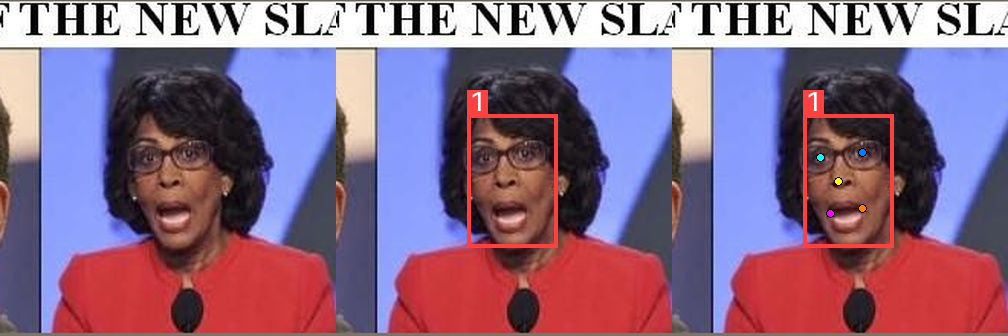

In [ ]:
import os
from PIL import Image
k = sorted(os.listdir('/content/ctx_core/overlay/overlays'))[5]
d = f'/content/ctx_core/overlay/overlays/{k}'
ims = [Image.open(f'{d}/{c}.png') for c in ('plain','box_number','sov')]
canvas = Image.new('RGB', (336*3, 336))
for i, im in enumerate(ims): canvas.paste(im, (336*i, 0))
canvas

In [ ]:
!pip install -q -U transformers accelerate bitsandbytes
!python 06_score_labels.py --model llava15 --overlay_root /content/ctx_core/overlay --jobs /content/ctx_core/overlay/prompts/jobs_core.jsonl --out_dir /content/drive/MyDrive/sov/results_core

6428 job(s) | model=llava15 | out_dir=/content/drive/MyDrive/sov/results_core
processor_config.json: 100% 173/173 [00:00<00:00, 915kB/s]
chat_template.json: 100% 701/701 [00:00<00:00, 3.27MB/s]
chat_template.jinja: 100% 674/674 [00:00<00:00, 4.54MB/s]
preprocessor_config.json: 100% 505/505 [00:00<00:00, 3.31MB/s]
config.json: 100% 950/950 [00:00<00:00, 6.27MB/s]
tokenizer_config.json: 100% 1.45k/1.45k [00:00<00:00, 6.04MB/s]
tokenizer.json: 100% 3.62M/3.62M [00:00<00:00, 113MB/s]

tokenizer.model: downloading bytes:   0% 0.00/500k [00:00<?, ?B/s]
tokenizer.model: downloading bytes: 100% 346k/346k [00:00<00:00, 488kB/s, 34.2kB/s  ]
tokenizer.model: reconstructing file: 100% 500k/500k [00:00<00:00, 704kB/s, 49.3kB/s  ]
added_tokens.json: 100% 41.0/41.0 [00:00<00:00, 278kB/s]
special_tokens_map.json: 100% 552/552 [00:00<00:00, 3.12MB/s]
model.safetensors.index.json: 100% 70.1k/70.1k [00:00<00:00, 153MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetc

In [ ]:
!pip list 2>/dev/null | grep -i -E "^(transformers|torch|bitsandbytes|accelerate|retina-face|tensorflow|keras|tf-keras) "

accelerate                            1.15.0
bitsandbytes                          0.50.2
keras                                 3.13.2
retina-face                           0.0.19
tensorflow                            2.21.0
torch                                 2.11.0+cu130
transformers                          5.21.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving 08_analysis.py to 08_analysis.py


In [ ]:
!find /content/drive/MyDrive -name "results_llava15_jobs_core.jsonl"
!find /content/drive/MyDrive -name "core_set.csv"
!find /content/drive/MyDrive -name "results_llava15_jobs_dev.jsonl"

/content/drive/MyDrive/sov/results_core/results_llava15_jobs_core.jsonl
/content/drive/MyDrive/sov/results/results_llava15_jobs_dev.jsonl


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving core_set.csv to core_set.csv


In [ ]:
!python /content/08_analysis.py \
  --core_results "/content/drive/MyDrive/sov/results_core/results_llava15_jobs_core.jsonl" \
  --core_set "/content/core_set.csv" \
  --dev_results "/content/drive/MyDrive/sov/results/results_llava15_jobs_dev.jsonl" \
  --out_dir "/content/drive/MyDrive/sov_results/analysis" \
  --boot 2000

# Analysis summary (auto-generated)

Faces: 1473 | images: 1461 | bootstrap: 2000 resamples of images | seed 42

## Overall balanced accuracy (95% CI)
- raw, 7 classes: Plain 0.428 [0.410, 0.447], Box 0.419 [0.401, 0.438], Box+Number 0.417 [0.398, 0.435], SoV 0.374 [0.355, 0.394]
- raw, without Neutral: Plain 0.500 [0.479, 0.521], Box 0.489 [0.468, 0.511], Box+Number 0.486 [0.465, 0.508], SoV 0.437 [0.414, 0.460]
- self-calibrated, 7 classes: Plain 0.468 [0.445, 0.492], Box 0.483 [0.459, 0.506], Box+Number 0.482 [0.459, 0.505], SoV 0.446 [0.423, 0.469]

## Paired differences, balanced accuracy, points (95% CI)
- **raw, all7**: sov - plain -5.4 [-7.3, -3.5]; box - plain -0.9 [-2.0, +0.2]; box_number - plain -1.2 [-2.3, +0.0]; box_number - box -0.2 [-1.1, +0.7]; sov - box_number -4.2 [-6.0, -2.4]
- **raw, no_neutral**: sov - plain -6.3 [-8.5, -4.1]; box - plain -1.1 [-2.4, +0.2]; box_number - plain -1.3 [-2.7, +0.0]; box_number - box -0.3 [-1.2, +0.8]; sov - box_number -5.0 [-7.0, -2.8]


In [ ]:
!pip install -q retina-face tf-keras

In [1]:
from google.colab import drive; drive.mount('/content/drive')
!mkdir -p /content/ctx_multi
!unzip -q /content/drive/MyDrive/sov/multi_group_images.zip -d /content/ctx_multi
!cp /content/drive/MyDrive/sov/*.py /content/
%cd /content
!pip install -q retina-face tf-keras

Mounted at /content/drive
/content


In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp /content/drive/MyDrive/sov/*.py /content/
%cd /content

/content


In [11]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [ ]:
!python sov_stage1_2_detect.py --input /content/ctx_multi/images --output /content/ctx_multi/det
!cp -r /content/ctx_multi/det /content/drive/MyDrive/sov/ctx_multi_det

13:00:21 INFO Found 1250 image(s). Settings: {'backend': 'retinaface', 'threshold': 0.9, 'max_side': 1600}
26-10-29 13:00:26 - Directory /root/.deepface/weights created
26-10-29 13:00:26 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5
100% 119M/119M [00:00<00:00, 216MB/s]
13:00:31 INFO [1/1250] m00000.jpg: 9 face(s) in 3.9s
13:00:32 INFO [2/1250] m00001.jpg: 2 face(s) in 0.2s
13:00:32 INFO [3/1250] m00002.jpg: 9 face(s) in 0.2s
13:00:32 INFO [4/1250] m00003.jpg: 2 face(s) in 0.2s
13:00:32 INFO [5/1250] m00004.jpg: 3 face(s) in 0.2s
13:00:32 INFO [6/1250] m00005.jpg: 2 face(s) in 0.2s
13:00:33 INFO [7/1250] m00006.jpg: 2 face(s) in 0.2s
13:00:33 INFO [8/1250] m00007.jpg: 6 face(s) in 0.2s
13:00:33 INFO [9/1250] m00008.jpg: 6 face(s) in 0.2s
13:00:33 INFO [10/1250] m

In [ ]:
!python sov_stage3_5_overlay_scaled.py --input /content/ctx_multi/images --detections /content/ctx_multi/det/detections --output /content/ctx_multi/overlay --eps 0.4
!python 11_match_multiface_jobs.py --targets /content/ctx_multi/targets_view.csv --overlay_root /content/ctx_multi/overlay --name multi_even --chunk_mod 2 --chunk_rem 0

13:08:26 INFO Found 1250 detection file(s). Settings: {'eps': 0.4, 'style_version': 2, 'numbering': 'left_to_right', 'spec': 'scaled', 'line_frac': 0.03, 'dot_frac': 0.025, 'tag_frac': 0.28, 'shuffle_numbers': None}
13:08:26 INFO [1/1250] m00000.jpg: 9 detected -> 9 final (0 dropped) in 0.2s
13:08:27 INFO [2/1250] m00001.jpg: 2 detected -> 2 final (0 dropped) in 0.2s
13:08:27 INFO [3/1250] m00002.jpg: 9 detected -> 9 final (0 dropped) in 0.1s
13:08:27 INFO [4/1250] m00003.jpg: 2 detected -> 2 final (0 dropped) in 0.1s
13:08:27 INFO [5/1250] m00004.jpg: 3 detected -> 3 final (0 dropped) in 0.1s
13:08:27 INFO [6/1250] m00005.jpg: 2 detected -> 2 final (0 dropped) in 0.1s
13:08:27 INFO [7/1250] m00006.jpg: 2 detected -> 2 final (0 dropped) in 0.1s
13:08:27 INFO [8/1250] m00007.jpg: 6 detected -> 6 final (0 dropped) in 0.2s
13:08:27 INFO [9/1250] m00008.jpg: 6 detected -> 6 final (0 dropped) in 0.1s
13:08:28 INFO [10/1250] m00009.jpg: 2 detected -> 2 final (0 dropped) in 0.2s
13:08:28 INFO

In [ ]:
!pip install -q -U transformers accelerate bitsandbytes
!python 06_score_labels.py --model llava15 --overlay_root /content/ctx_multi/overlay --jobs /content/ctx_multi/overlay/prompts/jobs_multi_even.jsonl --out_dir /content/drive/MyDrive/sov/results_multi_even

6858 job(s) | model=llava15 | out_dir=/content/drive/MyDrive/sov/results_multi_even
processor_config.json: 100% 173/173 [00:00<00:00, 802kB/s]
chat_template.json: 100% 701/701 [00:00<00:00, 2.57MB/s]
chat_template.jinja: 100% 674/674 [00:00<00:00, 4.60MB/s]
preprocessor_config.json: 100% 505/505 [00:00<00:00, 2.65MB/s]
config.json: 100% 950/950 [00:00<00:00, 4.88MB/s]
tokenizer_config.json: 100% 1.45k/1.45k [00:00<00:00, 900kB/s]
tokenizer.json: 100% 3.62M/3.62M [00:00<00:00, 197MB/s]

tokenizer.model: downloading bytes:   0% 0.00/500k [00:00<?, ?B/s]
tokenizer.model: downloading bytes: 100% 346k/346k [00:01<00:00, 260kB/s, 33.5kB/s  ]
tokenizer.model: reconstructing file: 100% 500k/500k [00:01<00:00, 375kB/s, 48.3kB/s  ]
added_tokens.json: 100% 41.0/41.0 [00:00<00:00, 179kB/s]
special_tokens_map.json: 100% 552/552 [00:00<00:00, 2.82MB/s]
model.safetensors.index.json: 100% 70.1k/70.1k [00:00<00:00, 163MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            


In [ ]:
!mkdir -p /content/drive/MyDrive/sov/multiface
!cp /content/ctx_multi/overlay/prompts/jobs_multi_even.jsonl /content/drive/MyDrive/sov/multiface/
!cp /content/ctx_multi/overlay/summary.csv /content/drive/MyDrive/sov/multiface/
!cp /content/ctx_multi/targets_view.csv /content/drive/MyDrive/sov/multiface/

In [ ]:
import os

paths = [
    "/content/ctx_core",
    "/content/ctx_core/images",
    "/content/ctx_core/det/detections",
    "/content/ctx_core/targets.csv",
]

for path in paths:
    print(os.path.exists(path), path)

True /content/ctx_core
False /content/ctx_core/images
False /content/ctx_core/det/detections
False /content/ctx_core/targets.csv


In [ ]:
import os

path = "/content/drive/MyDrive/sov/probe"

print("Output folder exists:", os.path.exists(path))

if os.path.exists(path):
    for name in os.listdir(path):
        print(name)

Output folder exists: False


In [ ]:
!python sov_stage3_5_overlay_scaled.py --input /content/ctx_multi/images --detections /content/ctx_multi/det/detections --output /content/ctx_multi/overlay_shuffled --shuffle_numbers 7
!python 12_tag_probe.py --overlay_root /content/ctx_multi/overlay_shuffled --model llava15 --out_dir /content/drive/MyDrive/sov/probe --n_images 150

14:59:01 INFO Found 1250 detection file(s). Settings: {'eps': 0.4, 'style_version': 2, 'numbering': 'left_to_right', 'spec': 'scaled', 'line_frac': 0.03, 'dot_frac': 0.025, 'tag_frac': 0.28, 'shuffle_numbers': 7}
14:59:01 INFO [1/1250] m00000.jpg: 9 detected -> 9 final (0 dropped) in 0.2s
14:59:01 INFO [2/1250] m00001.jpg: 2 detected -> 2 final (0 dropped) in 0.2s
14:59:01 INFO [3/1250] m00002.jpg: 9 detected -> 9 final (0 dropped) in 0.2s
14:59:01 INFO [4/1250] m00003.jpg: 2 detected -> 2 final (0 dropped) in 0.1s
14:59:01 INFO [5/1250] m00004.jpg: 3 detected -> 3 final (0 dropped) in 0.1s
14:59:01 INFO [6/1250] m00005.jpg: 2 detected -> 2 final (0 dropped) in 0.1s
14:59:02 INFO [7/1250] m00006.jpg: 2 detected -> 2 final (0 dropped) in 0.1s
14:59:02 INFO [8/1250] m00007.jpg: 6 detected -> 6 final (0 dropped) in 0.2s
14:59:02 INFO [9/1250] m00008.jpg: 6 detected -> 6 final (0 dropped) in 0.1s
14:59:02 INFO [10/1250] m00009.jpg: 2 detected -> 2 final (0 dropped) in 0.2s
14:59:02 INFO [1

In [2]:
import os
import zipfile
import shutil

zip_path = (
    "/content/drive/MyDrive/sov/ctx_core_backup/"
    "core_set_context_images.zip"
)
restore_dir = "/content/ctx_core_restore"
core_dir = "/content/ctx_core"

assert os.path.isfile(zip_path), f"ZIP not found: {zip_path}"

os.makedirs(restore_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    assert bad_file is None, f"Corrupt ZIP member: {bad_file}"
    z.extractall(restore_dir)

# Find targets.csv and the images directory in the extracted archive
targets_candidates = []
image_dirs = []

for root, dirs, files in os.walk(restore_dir):
    if "targets.csv" in files:
        targets_candidates.append(os.path.join(root, "targets.csv"))

    if any(f.lower().endswith((".jpg", ".jpeg", ".png"))
           for f in files):
        image_dirs.append(root)

print("Targets candidates:", targets_candidates)
print("Directories containing images:", image_dirs[:10])

Targets candidates: ['/content/ctx_core_restore/targets.csv']
Directories containing images: ['/content/ctx_core_restore/images']


In [3]:
import os
import shutil

targets_src = "/content/ctx_core_restore/targets.csv"  # EDIT if nested
images_src = "/content/ctx_core_restore/images"        # EDIT if nested

targets_dst = "/content/ctx_core/targets.csv"
images_dst = "/content/ctx_core/images"

os.makedirs("/content/ctx_core", exist_ok=True)

assert os.path.isfile(targets_src), f"Missing: {targets_src}"
assert os.path.isdir(images_src), f"Missing: {images_src}"

if not os.path.exists(targets_dst):
    shutil.copy2(targets_src, targets_dst)
else:
    print("targets.csv already exists; leaving it unchanged.")

if not os.path.exists(images_dst):
    shutil.copytree(images_src, images_dst)
else:
    print("Images directory already exists; leaving it unchanged.")

print("Restoration step complete.")

Restoration step complete.


In [4]:
import os
import pandas as pd

core = "/content/ctx_core"

targets_path = f"{core}/targets.csv"
images_path = f"{core}/images"
detections_path = f"{core}/det/detections"

targets = pd.read_csv(targets_path)

images = [
    f for f in os.listdir(images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

detections = [
    f for f in os.listdir(detections_path)
    if f.endswith(".json")
]

print("Target rows:", len(targets))
print("Target columns:", targets.columns.tolist())
print("Images:", len(images))
print("Detection JSONs:", len(detections))
print("Sample image names:", images[:5])
print("Sample detection names:", detections[:5])

FileNotFoundError: [Errno 2] No such file or directory: '/content/ctx_core/det/detections'

In [ ]:
!python /content/sov_stage3_5_overlay_scaled.py --input /content/ctx_core/images --detections /content/ctx_core/det/detections --output /content/ctx_core/overlay_halfdots --eps 0.4 --dot_frac 0.0125

19:55:01 INFO Found 1473 detection file(s). Settings: {'eps': 0.4, 'style_version': 2, 'numbering': 'left_to_right', 'spec': 'scaled', 'line_frac': 0.03, 'dot_frac': 0.0125, 'tag_frac': 0.28, 'shuffle_numbers': None}
19:55:01 INFO [1/1473] 000000.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
19:55:02 INFO [2/1473] 000005.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
19:55:02 INFO [3/1473] 000007.jpg: 1 detected -> 1 final (0 dropped) in 0.1s
19:55:02 INFO [4/1473] 000009.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
19:55:02 INFO [5/1473] 000014.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
19:55:03 INFO [6/1473] 000015.jpg: 1 detected -> 1 final (0 dropped) in 0.3s
19:55:03 INFO [7/1473] 000020.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
19:55:03 INFO [8/1473] 000027.jpg: 2 detected -> 2 final (0 dropped) in 0.3s
19:55:03 INFO [9/1473] 000043.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
19:55:04 INFO [10/1473] 000048.jpg: 1 detected -> 1 final (0 dropped) in 0.3s
19:55:04 INF

In [ ]:
!python /content/05_match_and_jobs.py --targets /content/ctx_core/targets.csv --overlay_root /content/ctx_core/overlay_halfdots --name core_halfdots --variants A --conditions sov --numbered

targets: 1473 | matched: 1473 (100.0%) | jobs: 1741
not matched, by reason: {}
IoU of matched faces, quantiles 10/50/90: [0.55, 0.66, 0.75]
ambiguous matches (2nd best IoU > 70% of best): 0

match rate by race_group:
race_group
Asian             100.0
Black             100.0
Caucasian-like    100.0

match rate by gender15:
gender15
Female    100.0
Male      100.0

match rate by expression_name:
expression_name
angry       100.0
disgust     100.0
fear        100.0
happy       100.0
neutral     100.0
sad         100.0
surprise    100.0

jobs file: /content/ctx_core/overlay_halfdots/prompts/jobs_core_halfdots.jsonl


In [ ]:
!python /content/06_score_labels.py --model llava15 --overlay_root /content/ctx_core/overlay_halfdots --jobs /content/ctx_core/overlay_halfdots/prompts/jobs_core_halfdots.jsonl --out_dir /content/drive/MyDrive/sov/results_core_halfdots

1741 job(s) | model=llava15 | out_dir=/content/drive/MyDrive/sov/results_core_halfdots
processor_config.json: 100% 173/173 [00:00<00:00, 323kB/s]
chat_template.json: 100% 701/701 [00:00<00:00, 1.90MB/s]
chat_template.jinja: 100% 674/674 [00:00<00:00, 2.80MB/s]
preprocessor_config.json: 100% 505/505 [00:00<00:00, 1.83MB/s]
config.json: 100% 950/950 [00:00<00:00, 2.87MB/s]
tokenizer_config.json: 100% 1.45k/1.45k [00:00<00:00, 3.55MB/s]
tokenizer.json: 100% 3.62M/3.62M [00:00<00:00, 68.1MB/s]

tokenizer.model: downloading bytes:   0% 0.00/500k [00:00<?, ?B/s]
tokenizer.model: downloading bytes: 100% 346k/346k [00:00<00:00, 659kB/s, 34.3kB/s  ]
tokenizer.model: reconstructing file: 100% 500k/500k [00:00<00:00, 950kB/s, 49.4kB/s  ]
added_tokens.json: 100% 41.0/41.0 [00:00<00:00, 175kB/s]
special_tokens_map.json: 100% 552/552 [00:00<00:00, 1.59MB/s]
Traceback (most recent call last):
  File "/content/06_score_labels.py", line 447, in <module>
    main()
    ~~~~^^
  File "/content/06_score_l

In [ ]:
import os

base = "/content/drive/MyDrive/sov"

for root, dirs, files in os.walk(base):
    for name in files:
        if "match" in name.lower() and name.lower().endswith(".csv"):
            print(os.path.join(root, name))

/content/drive/MyDrive/sov/ctx_dev/overlay/prompts/matches_dev.csv
/content/drive/MyDrive/sov/ctx_core_backup/prompts/matches_core.csv


In [ ]:
import os

base = "/content/drive/MyDrive/sov"

for root, dirs, files in os.walk(base):
    for name in files:
        if (
            "matches_multi" in name.lower()
            or "overlay" in name.lower()
            or "multi_even" in name.lower()
        ):
            print(os.path.join(root, name))

/content/drive/MyDrive/sov/Sov_stage3_5_overlay.py
/content/drive/MyDrive/sov/results_multi_even/results_llava15_jobs_multi_even.jsonl
/content/drive/MyDrive/sov/multiface/jobs_multi_even.jsonl


In [ ]:
!python /content/sov_stage3_5_overlay_scaled.py \
  --input /content/ctx_multi/images \
  --detections /content/ctx_multi/det/detections \
  --output /content/ctx_multi/overlay \
  --eps 0.4

Traceback (most recent call last):
  File "/content/sov_stage3_5_overlay_scaled.py", line 443, in <module>
    main()
    ~~~~^^
  File "/content/sov_stage3_5_overlay_scaled.py", line 438, in main
    run(args.input, args.detections, args.output, args.eps, args.force, args.limit,
    ~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        args.shuffle_numbers, args.line_frac, args.dot_frac, args.tag_frac)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/sov_stage3_5_overlay_scaled.py", line 335, in run
    raise FileNotFoundError(f"Detections folder not found: {detections_dir}")
FileNotFoundError: Detections folder not found: /content/ctx_multi/det/detections


Running using QWEN model

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!unzip -q "/content/phase 2 code.zip" -d /content/phase2
!unzip -q "/content/sov pipeline.zip" -d /content/sovsrc

In [3]:
!cp "/content/phase2/phase 2 code/"*.py /content/

!cp "/content/sovsrc/sov pipeline/sov_stage1_2_detect.py" /content/
!cp "/content/sovsrc/sov pipeline/Sov_stage3_5_overlay.py" /content/

In [4]:
!pip install -q -U transformers accelerate bitsandbytes
!pip install -q retina-face tf-keras

In [5]:
!find /content/drive/MyDrive/sov \
  \( -name "multi_group_images.zip" \
  -o -name "multi_faces.csv" \
  -o -name "targets_view.csv" \
  -o -name "sov_stage3_5_overlay_scaled.py" \)

/content/drive/MyDrive/sov/multi_group_images.zip
/content/drive/MyDrive/sov/multiface/targets_view.csv


In [6]:
!mkdir -p /content/ctx_multi

!unzip -q \
  /content/drive/MyDrive/sov/multi_group_images.zip \
  -d /content/ctx_multi

In [7]:
import os

print("Images:", os.path.isdir("/content/ctx_multi/images"))
print("Targets:", os.path.isfile("/content/ctx_multi/targets_view.csv"))

print("Image count:", len(os.listdir("/content/ctx_multi/images")))

Images: True
Targets: True
Image count: 1250


In [8]:
!python /content/09_build_multiface_set.py \
  --ff15 /content/phase2/phase\ 2\ code/fairface_all_1.csv \
  --ff25 /content/phase2/phase\ 2\ code/fairface_all.csv \
  --dev_set /content/phase2/phase\ 2\ code/dev_set.csv \
  --out_dir /content/multiface

seed=42 group_thr=0.5 view_margin=0.15 min_face_px=32.0 images_per_chunk=40
target faces before the size rule: 19462 | dropped for being < 32px in the view: 574
IMAGES: 1250 (mixed-emotion 428, other 822) | TARGET FACES: 2818 (in mixed images: 998)
chunks: 32 (the first 11 are mixed-emotion images)
targets per image: {2: 1017, 3: 175, 4: 42, 5: 10, 6: 2, 7: 3, 8: 1}
face size in the 336 view (px) quantiles 10/25/50/75/90: [41.0, 52.0, 74.0, 104.0, 127.0]
emotion mix (all targets): {'happy': 1806, 'neutral': 710, 'surprise': 95, 'sad': 92, 'disgust': 69, 'angry': 37, 'fear': 9}
emotion mix (mixed images): {'happy': 406, 'neutral': 367, 'surprise': 69, 'disgust': 59, 'sad': 59, 'angry': 31, 'fear': 7}

group x emotion (all target faces):
expression_name  angry  disgust  fear  happy  sad  surprise  neutral
race_group                                                          
Asian                5       13     0    382   20        18      161
Black                0       11     0    204   

In [9]:
!python /content/10_make_group_images.py \
  --multi_csv /content/multiface/multi_faces.csv \
  --img_dir "/path/to/your/original/ExpW/images" \
  --out_dir /content/ctx_multi

2818 target faces in 1250 images | size=336 workers=1
  250/1250 images (2s)
  500/1250 images (2s)
  750/1250 images (2s)
  1000/1250 images (2s)
  1250/1250 images (2s)

=== SUMMARY ===
ok faces: 0 | failed: 2818 {'image_open_failed': 2818}
images written: 0
Traceback (most recent call last):
  File "/content/10_make_group_images.py", line 113, in <module>
    sys.exit(main())
             ~~~~^^
  File "/content/10_make_group_images.py", line 106, in main
    tv.face_px_check.quantile([.1, .5, .9]).round(0).tolist())
    ^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/pandas/core/generic.py", line 6299, in __getattr__
    return object.__getattribute__(self, name)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^
AttributeError: 'DataFrame' object has no attribute 'face_px_check'. Did you mean: 'face_px_view'?


In [12]:
!python /content/sov_stage1_2_detect.py \
  --input /content/ctx_multi/images \
  --output /content/ctx_multi/det

16:53:24 INFO Found 1250 image(s). Settings: {'backend': 'retinaface', 'threshold': 0.9, 'max_side': 1600}
26-10-30 16:53:27 - Directory /root/.deepface/weights created
26-10-30 16:53:27 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5
100% 119M/119M [00:00<00:00, 120MB/s]
16:53:33 INFO [1/1250] m00000.jpg: 9 face(s) in 3.4s
16:53:33 INFO [2/1250] m00001.jpg: 2 face(s) in 0.2s
16:53:33 INFO [3/1250] m00002.jpg: 9 face(s) in 0.2s
16:53:33 INFO [4/1250] m00003.jpg: 2 face(s) in 0.2s
16:53:33 INFO [5/1250] m00004.jpg: 3 face(s) in 0.2s
16:53:34 INFO [6/1250] m00005.jpg: 2 face(s) in 0.2s
16:53:34 INFO [7/1250] m00006.jpg: 2 face(s) in 0.2s
16:53:34 INFO [8/1250] m00007.jpg: 6 face(s) in 0.2s
16:53:34 INFO [9/1250] m00008.jpg: 6 face(s) in 0.2s
16:53:34 INFO [10/1250] m

In [13]:
!python /content/sov_stage3_5_overlay_scaled.py \
  --input /content/ctx_multi/images \
  --detections /content/ctx_multi/det/detections \
  --output /content/ctx_multi/overlay \
  --eps 0.4

16:58:22 INFO Found 1250 detection file(s). Settings: {'eps': 0.4, 'style_version': 2, 'numbering': 'left_to_right', 'spec': 'scaled', 'line_frac': 0.03, 'dot_frac': 0.025, 'tag_frac': 0.28, 'shuffle_numbers': None}
16:58:22 INFO [1/1250] m00000.jpg: 9 detected -> 9 final (0 dropped) in 0.3s
16:58:23 INFO [2/1250] m00001.jpg: 2 detected -> 2 final (0 dropped) in 0.4s
16:58:23 INFO [3/1250] m00002.jpg: 9 detected -> 9 final (0 dropped) in 0.2s
16:58:23 INFO [4/1250] m00003.jpg: 2 detected -> 2 final (0 dropped) in 0.1s
16:58:23 INFO [5/1250] m00004.jpg: 3 detected -> 3 final (0 dropped) in 0.1s
16:58:23 INFO [6/1250] m00005.jpg: 2 detected -> 2 final (0 dropped) in 0.1s
16:58:23 INFO [7/1250] m00006.jpg: 2 detected -> 2 final (0 dropped) in 0.1s
16:58:24 INFO [8/1250] m00007.jpg: 6 detected -> 6 final (0 dropped) in 0.2s
16:58:24 INFO [9/1250] m00008.jpg: 6 detected -> 6 final (0 dropped) in 0.1s
16:58:24 INFO [10/1250] m00009.jpg: 2 detected -> 2 final (0 dropped) in 0.2s
16:58:24 INFO

In [23]:
!python /content/sov_stage1_2_detect.py \
  --input /content/ctx_multi/images \
  --output /content/ctx_multi/det \
  --backend retinaface \
  --threshold 0.5 \
  --max_side 1600

17:09:29 INFO Found 1250 image(s). Settings: {'backend': 'retinaface', 'threshold': 0.5, 'max_side': 1600}
17:09:35 INFO [1/1250] m00000.jpg: 10 face(s) in 2.6s
17:09:35 INFO [2/1250] m00001.jpg: 2 face(s) in 0.2s
17:09:35 INFO [3/1250] m00002.jpg: 9 face(s) in 0.2s
17:09:35 INFO [4/1250] m00003.jpg: 2 face(s) in 0.2s
17:09:36 INFO [5/1250] m00004.jpg: 3 face(s) in 0.2s
17:09:36 INFO [6/1250] m00005.jpg: 2 face(s) in 0.2s
17:09:36 INFO [7/1250] m00006.jpg: 2 face(s) in 0.2s
17:09:36 INFO [8/1250] m00007.jpg: 7 face(s) in 0.2s
17:09:36 INFO [9/1250] m00008.jpg: 6 face(s) in 0.2s
17:09:37 INFO [10/1250] m00009.jpg: 2 face(s) in 0.2s
17:09:37 INFO [11/1250] m00010.jpg: 2 face(s) in 0.2s
17:09:37 INFO [12/1250] m00011.jpg: 3 face(s) in 0.2s
17:09:37 INFO [13/1250] m00012.jpg: 3 face(s) in 0.2s
17:09:37 INFO [14/1250] m00013.jpg: 2 face(s) in 0.2s
17:09:37 INFO [15/1250] m00014.jpg: 2 face(s) in 0.2s
17:09:38 INFO [16/1250] m00015.jpg: 2 face(s) in 0.2s
17:09:38 INFO [17/1250] m00016.jpg: 3

In [25]:
!mkdir -p /content/drive/MyDrive/sov/phase2_backup

!cp -r /content/ctx_multi/det \
  /content/drive/MyDrive/sov/phase2_backup/

In [27]:
!python /content/sov_stage3_5_overlay_scaled.py \
  --input /content/ctx_multi/images \
  --detections /content/ctx_multi/det/detections \
  --output /content/ctx_multi/overlay \
  --eps 0.4

17:17:12 INFO Found 1250 detection file(s). Settings: {'eps': 0.4, 'style_version': 2, 'numbering': 'left_to_right', 'spec': 'scaled', 'line_frac': 0.03, 'dot_frac': 0.025, 'tag_frac': 0.28, 'shuffle_numbers': None}
17:17:12 INFO [1/1250] skip (already done): m00000.jpg
17:17:12 INFO [2/1250] skip (already done): m00001.jpg
17:17:12 INFO [3/1250] skip (already done): m00002.jpg
17:17:12 INFO [4/1250] skip (already done): m00003.jpg
17:17:12 INFO [5/1250] skip (already done): m00004.jpg
17:17:12 INFO [6/1250] skip (already done): m00005.jpg
17:17:12 INFO [7/1250] skip (already done): m00006.jpg
17:17:12 INFO [8/1250] skip (already done): m00007.jpg
17:17:12 INFO [9/1250] skip (already done): m00008.jpg
17:17:12 INFO [10/1250] skip (already done): m00009.jpg
17:17:12 INFO [11/1250] skip (already done): m00010.jpg
17:17:12 INFO [12/1250] skip (already done): m00011.jpg
17:17:12 INFO [13/1250] skip (already done): m00012.jpg
17:17:12 INFO [14/1250] skip (already done): m00013.jpg
17:17:12 

In [29]:
!python /content/11_match_multiface_jobs.py \
  --targets /content/ctx_multi/targets_view.csv \
  --overlay_root /content/ctx_multi/overlay \
  --name multi_even \
  --chunk_mod 2 \
  --chunk_rem 0

target faces: 2818 | matched: 2816 (99.9%) | jobs written: 6858 (chunk_mod=2, chunk_rem=0)
not matched, by reason: {'no_unique_match': 2}
IoU of matched faces, quantiles 10/50/90: [0.58, 0.69, 0.77]
images where the detector found a different number of faces than we have targets: 1206 faces of 2816

match rate by race_group:
race_group
Asian              99.8
Black             100.0
Caucasian-like     99.9

match rate by gender15:
gender15
Female    99.9
Male      99.9

match rate by mixed:
mixed
False    99.9
True     99.9

match rate by face size in the view:
size_tier
small      99.9
medium    100.0
large      99.9

jobs file: /content/ctx_multi/overlay/prompts/jobs_multi_even.jsonl


In [30]:
!pip install -q -U transformers accelerate bitsandbytes

In [31]:
!python /content/06_score_labels.py --model qwen25vl --check_tokens

preprocessor_config.json: 100% 350/350 [00:00<00:00, 1.49MB/s]
chat_template.json: 100% 1.05k/1.05k [00:00<00:00, 3.46MB/s]
config.json: 100% 1.37k/1.37k [00:00<00:00, 4.34MB/s]
tokenizer_config.json: 100% 5.70k/5.70k [00:00<00:00, 16.5MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 69.9MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 118MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 142MB/s]
Angry     ids=[524, 10743, 18514, 77818] tokens=['ang', 'Ang', 'Ġangry', 'ĠAngry']
Disgust   ids=[4093, 4243, 4839, 67062] tokens=['ĠDis', 'dis', 'Dis', 'Ġdisgust']
Fear      ids=[69, 8679, 41967, 90371] tokens=['f', 'Ġfear', 'ĠFear', 'Fear']
Happy     ids=[6247, 23355, 32847, 56521] tokens=['Ġhappy', 'ĠHappy', 'Happy', 'happy']
Sad       ids=[12421, 30681, 59665, 82114] tokens=['Ġsad', 'ĠSad', 'Sad', 'sad']
Surprise  ids=[12761, 19784, 23043, 84484] tokens=['Ġsurprise', 'sur', 'Sur', 'ĠSurprise']
Neutral   ids=[20628, 58694, 59568, 86907] tokens=['Ġneutral', 'ĠNeutral', 'neutral', 'Neutral

In [32]:
!python /content/06_score_labels.py \
  --model qwen25vl \
  --overlay_root /content/ctx_multi/overlay \
  --jobs /content/ctx_multi/overlay/prompts/jobs_multi_even.jsonl \
  --out_dir /content/drive/MyDrive/sov/qwen_smoke_test \
  --limit 20 \
  --also_generate

20 job(s) | model=qwen25vl | out_dir=/content/drive/MyDrive/sov/qwen_smoke_test
model.safetensors.index.json: 100% 57.6k/57.6k [00:00<00:00, 125MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0% 0/5 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/16.6G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/16.6G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/16.6G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/16.6G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/16.6G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 66.9M/16.6G [00:01<05:11, 52.9MB/s,  105kB/s  ] 
Reconstructing (incomplete total...):   2% 256M/16.6G [00:02<01:28, 184MB/s,  115MB/s  ]
Reconstructing (incomplete total...):   5% 829M/16.6G [00:06<02:02, 129MB/s, 80.7MB/s  ] 
Reconstructing (incomplete total...):   5% 897M/16.6G [00:07<01:41, 154MB/s,  129MB/s  ]
Reconst

In [33]:
!python /content/06_score_labels.py \
  --model qwen25vl \
  --overlay_root /content/ctx_multi/overlay \
  --jobs /content/ctx_multi/overlay/prompts/jobs_multi_even.jsonl \
  --out_dir /content/drive/MyDrive/sov/results_multi_even_qwen

6858 job(s) | model=qwen25vl | out_dir=/content/drive/MyDrive/sov/results_multi_even_qwen
Loading weights: 100% 729/729 [01:07<00:00, 10.83it/s]
0 already done, 6858 to run.
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
[25/6858] 0.47s/job (last 50) | ~0.89 h left
[50/6858] 0.45s/job (last 50) | ~0.85 h left
[75/6858] 0.43s/job (last 50) | ~0.82 h left
[100/6858] 0.45s/job (last 50) | ~0.84 h left
[125/6858] 0.47s/job (last 50) | ~0.87 h left
[150/6858] 0.49s/job (last 50) | ~0.91 h left
[175/6858] 0.49s/job (last 50) | ~0.90 h left
[200/6858] 0.47s/job (last 50) | ~0.87 h left
[225/6858] 0.46s/job (last 50) | ~0.85 h left
[250/6858] 0.45s/job (last 50) | ~0.83 h left
[275/6858] 0.45s/job (last 50) | ~0.83 h left
[300/6858] 0.46s/job (last 50) | ~0.84 h left
[325/6858] 0.46s/job (last 50) | ~0.84 h left
[350/6858] 0.47s/jo

In [34]:
!python /content/13_multiface_analysis.py \
  --results /content/drive/MyDrive/sov/results_multi_even_qwen/results_qwen25vl_jobs_multi_even.jsonl \
  --multi_faces /content/ctx_multi/targets_view.csv \
  --out_dir /content/drive/MyDrive/sov/analysis_multi_qwen \
  --boot 2000 \
  --seed 42

# Multi-face analysis summary (auto-generated)

Target faces with results: 1447 of 2818 | images: 640 (mixed: 228) | chunks present: [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10)]... (16 of 32) | bootstrap 2000 resamples of images

## Accuracy per arm (95% CI)
- **all / acc_all**: Plain (position) 0.666 [0.639, 0.694] (n=1447); Box (position) 0.657 [0.630, 0.683] (n=1447); Box+Number (number) 0.725 [0.700, 0.748] (n=1447); SoV (number) 0.522 [0.491, 0.552] (n=1447); Box+Number (position) 0.589 [0.549, 0.629] (n=535); SoV (position) 0.460 [0.417, 0.502] (n=535)
- **mixed / acc_all**: Plain (position) 0.518 [0.476, 0.557] (n=535); Box (position) 0.514 [0.473, 0.555] (n=535); Box+Number (number) 0.606 [0.567, 0.646] (n=535); SoV (number) 0.471 [0.429, 0.513] (n=535); Box+Number (position) 0.589 [0.549, 0.629] (n=535); SoV (position) 0.460 [0.417, 0.502] (n=535)
- **all / acc_expr**: Plain (position) 0.257 [0.172, 0.344] (n=175); Box (position) 0.234 [0.157

In [37]:
import os

paths = [
    "/content/ctx_core/det/detections",
    "/content/drive/MyDrive/sov/ctx_core/det/detections",
    "/content/drive/MyDrive/sov/ctx_core_backup/det/detections",
]

for path in paths:
    exists = os.path.isdir(path)
    count = len(os.listdir(path)) if exists else 0
    print(f"{'FOUND' if exists else 'MISSING'} | {count} files | {path}")

MISSING | 0 files | /content/ctx_core/det/detections
MISSING | 0 files | /content/drive/MyDrive/sov/ctx_core/det/detections
FOUND | 1473 files | /content/drive/MyDrive/sov/ctx_core_backup/det/detections


In [38]:
!mkdir -p /content/ctx_core/det
!cp -r /content/drive/MyDrive/sov/ctx_core_backup/det/detections /content/ctx_core/det/

In [41]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/sov/ctx_core_backup/core_set_context_images.zip"
output_dir = "/content/ctx_core/images"

os.makedirs(output_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(output_dir)

print("Extraction completed")
print("Extracted entries:", len(os.listdir(output_dir)))

Extraction completed
Extracted entries: 2


In [43]:
import shutil
import os

source = "/content/ctx_core/images/images"
destination = "/content/ctx_core/images"

for filename in os.listdir(source):
    shutil.move(
        os.path.join(source, filename),
        os.path.join(destination, filename)
    )

os.rmdir(source)

print("Image directory corrected.")
print("Files:", len(os.listdir(destination)))

Image directory corrected.
Files: 1474


In [44]:
print("Images:", len(os.listdir("/content/ctx_core/images")))
print("Detections:", len(os.listdir("/content/ctx_core/det/detections")))

Images: 1474
Detections: 1473


In [45]:
!python /content/sov_stage3_5_overlay_scaled.py \
  --input /content/ctx_core/images \
  --detections /content/ctx_core/det/detections \
  --output /content/ctx_core/overlay_halfdots \
  --eps 0.4 \
  --dot_frac 0.0125

18:51:16 INFO Found 1473 detection file(s). Settings: {'eps': 0.4, 'style_version': 2, 'numbering': 'left_to_right', 'spec': 'scaled', 'line_frac': 0.03, 'dot_frac': 0.0125, 'tag_frac': 0.28, 'shuffle_numbers': None}
18:51:16 INFO [1/1473] 000000.jpg: 1 detected -> 1 final (0 dropped) in 0.1s
18:51:17 INFO [2/1473] 000005.jpg: 1 detected -> 1 final (0 dropped) in 0.1s
18:51:17 INFO [3/1473] 000007.jpg: 1 detected -> 1 final (0 dropped) in 0.1s
18:51:17 INFO [4/1473] 000009.jpg: 1 detected -> 1 final (0 dropped) in 0.1s
18:51:17 INFO [5/1473] 000014.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
18:51:17 INFO [6/1473] 000015.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
18:51:17 INFO [7/1473] 000020.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
18:51:18 INFO [8/1473] 000027.jpg: 2 detected -> 2 final (0 dropped) in 0.2s
18:51:18 INFO [9/1473] 000043.jpg: 1 detected -> 1 final (0 dropped) in 0.1s
18:51:18 INFO [10/1473] 000048.jpg: 1 detected -> 1 final (0 dropped) in 0.2s
18:51:18 INF

In [47]:
!python /content/05_match_and_jobs.py \
  --targets /content/targets.csv \
  --overlay_root /content/ctx_core/overlay_halfdots \
  --name core_halfdots \
  --variants A \
  --conditions sov \
  --numbered

targets: 1473 | matched: 1473 (100.0%) | jobs: 1741
not matched, by reason: {}
IoU of matched faces, quantiles 10/50/90: [0.55, 0.66, 0.75]
ambiguous matches (2nd best IoU > 70% of best): 0

match rate by race_group:
race_group
Asian             100.0
Black             100.0
Caucasian-like    100.0

match rate by gender15:
gender15
Female    100.0
Male      100.0

match rate by expression_name:
expression_name
angry       100.0
disgust     100.0
fear        100.0
happy       100.0
neutral     100.0
sad         100.0
surprise    100.0

jobs file: /content/ctx_core/overlay_halfdots/prompts/jobs_core_halfdots.jsonl


In [48]:
!python /content/06_score_labels.py \
  --model qwen25vl \
  --overlay_root /content/ctx_core/overlay_halfdots \
  --jobs /content/ctx_core/overlay_halfdots/prompts/jobs_core_halfdots.jsonl \
  --out_dir /content/drive/MyDrive/sov/results_core_halfdots_qwen

1741 job(s) | model=qwen25vl | out_dir=/content/drive/MyDrive/sov/results_core_halfdots_qwen
Loading weights: 100% 729/729 [01:07<00:00, 10.75it/s]
0 already done, 1741 to run.
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
[25/1741] 0.46s/job (last 50) | ~0.22 h left
[50/1741] 0.42s/job (last 50) | ~0.20 h left
[75/1741] 0.39s/job (last 50) | ~0.18 h left
[100/1741] 0.40s/job (last 50) | ~0.18 h left
[125/1741] 0.40s/job (last 50) | ~0.18 h left
[150/1741] 0.41s/job (last 50) | ~0.18 h left
[175/1741] 0.42s/job (last 50) | ~0.18 h left
[200/1741] 0.43s/job (last 50) | ~0.18 h left
[225/1741] 0.44s/job (last 50) | ~0.19 h left
[250/1741] 0.45s/job (last 50) | ~0.19 h left
[275/1741] 0.46s/job (last 50) | ~0.19 h left
[300/1741] 0.48s/job (last 50) | ~0.19 h left
[325/1741] 0.48s/job (last 50) | ~0.19 h left
[350/1741] 0.47s

In [49]:
!python /content/06_score_labels.py \
  --model qwen25vl \
  --overlay_root /content/ctx_multi/overlay \
  --jobs /content/ctx_multi/overlay/prompts/jobs_multi_even.jsonl \
  --out_dir /content/drive/MyDrive/sov/results_multi_even_qwen

6858 job(s) | model=qwen25vl | out_dir=/content/drive/MyDrive/sov/results_multi_even_qwen
Loading weights: 100% 729/729 [01:08<00:00, 10.68it/s]
6858 already done, 0 to run.
results: /content/drive/MyDrive/sov/results_multi_even_qwen/results_qwen25vl_jobs_multi_even.jsonl


In [53]:
import os
import shutil

backup = "/content/drive/MyDrive/sov/ctx_dev"
target = "/content/ctx_dev"

folders = [
    ("det/detections", "det/detections"),
    ("overlay/final", "overlay/final"),
    ("overlay/prompts", "overlay/prompts"),
]

for src_rel, dst_rel in folders:
    src = os.path.join(backup, src_rel)
    dst = os.path.join(target, dst_rel)

    os.makedirs(os.path.dirname(dst), exist_ok=True)
    shutil.copytree(src, dst, dirs_exist_ok=True)

    print("Restored:", dst_rel)

Restored: det/detections
Restored: overlay/final
Restored: overlay/prompts


In [57]:
import zipfile

zip_path = "/content/dev_set_context_images.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist():
        if name.endswith("targets.csv"):
            print("Found:", name)

Found: targets.csv


In [61]:
import os

for root, dirs, files in os.walk("/content/ctx_dev"):
    image_count = sum(
        f.lower().endswith((".jpg", ".jpeg", ".png"))
        for f in files
    )

    if image_count:
        print(root, "|", image_count, "images")

/content/ctx_dev/images | 280 images


In [ ]:
!python /content/05_match_and_jobs.py \
  --targets /content/ctx_core/targets.csv \
  --overlay_root /content/ctx_core/overlay_halfdots \
  --name core_halfdots \
  --variants A \
  --conditions sov \
  --numbered